In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 设置画图风格
sns.set_theme(style="whitegrid")

# 读取数据，注意把第一列作为索引（解决作业里提到的“无实际预测意义的索引字段”问题）
# 请确保你的路径是正确的
df = pd.read_csv('../data/cs-training.csv', index_col=0)

# 查看前几行、行列数、数据类型
print(f"数据形状: {df.shape}")
display(df.head())
display(df.info())

数据形状: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


<class 'pandas.core.frame.DataFrame'>
Index: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: fl

None

In [6]:
import pandas as pd
#用 pandas 读入数据。检查前几行、行列数、字段名、数据类型。注意：CSV 里可能有一列无实际预测意义的索引字段；先识别它，不要直接把它当特征。
df=pd.read_csv('../data/cs-training.csv', index_col=0)
df.head(10)
df.shape
df.columns
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: fl

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [7]:
'''统计每列缺失数量和比例。
统计目标变量的类别数量和比例。
把缺失值结果按比例排序，写出你观察到的两点。
记录目标类别是否不平衡，以及这会怎样影响后续评价模型。
'''
missing_data=pd.DataFrame({
    '缺失数量':df.isnull().sum(),
    '缺失比例':(df.isnull().sum()/len(df))*100
})

missing_data=missing_data[missing_data['缺失数量']>0].sort_values(by='缺失比例',ascending=False)

print(missing_data)

                     缺失数量       缺失比例
MonthlyIncome       29731  19.820667
NumberOfDependents   3924   2.616000


In [8]:
# 1. 创建一个 DataFrame 集中管理
missing_data = pd.DataFrame({
    '缺失数量': df.isnull().sum(),
    '缺失比例(%)': (df.isnull().sum() / len(df)) * 100
})

# 2. 过滤掉没有缺失值的列，并按照缺失比例降序排列
missing_data = missing_data[missing_data['缺失数量'] > 0].sort_values(by='缺失比例(%)', ascending=False)

# 3. 打印结果
print(missing_data)

                     缺失数量    缺失比例(%)
MonthlyIncome       29731  19.820667
NumberOfDependents   3924   2.616000


monthlyincome的缺失比例明显较高，需进一步了解缺失情况，若无较合理的填充值，后续应删除对应行。
NumberOfDependents缺失比例只有2%，较少，可以直接删除对应行。


第 4 部分：探索变量，50 分钟

至少分析以下变量：
- 年龄；
- 月收入；
- 债务比率；
- 逾期 30–59 天次数；
- 逾期 90 天以上次数；
- 信用额度使用比例。
画两类图：数值变量的直方图，以及违约／未违约的简单对比图。每张图旁边用 Markdown 写一句解释，不要只贴图。

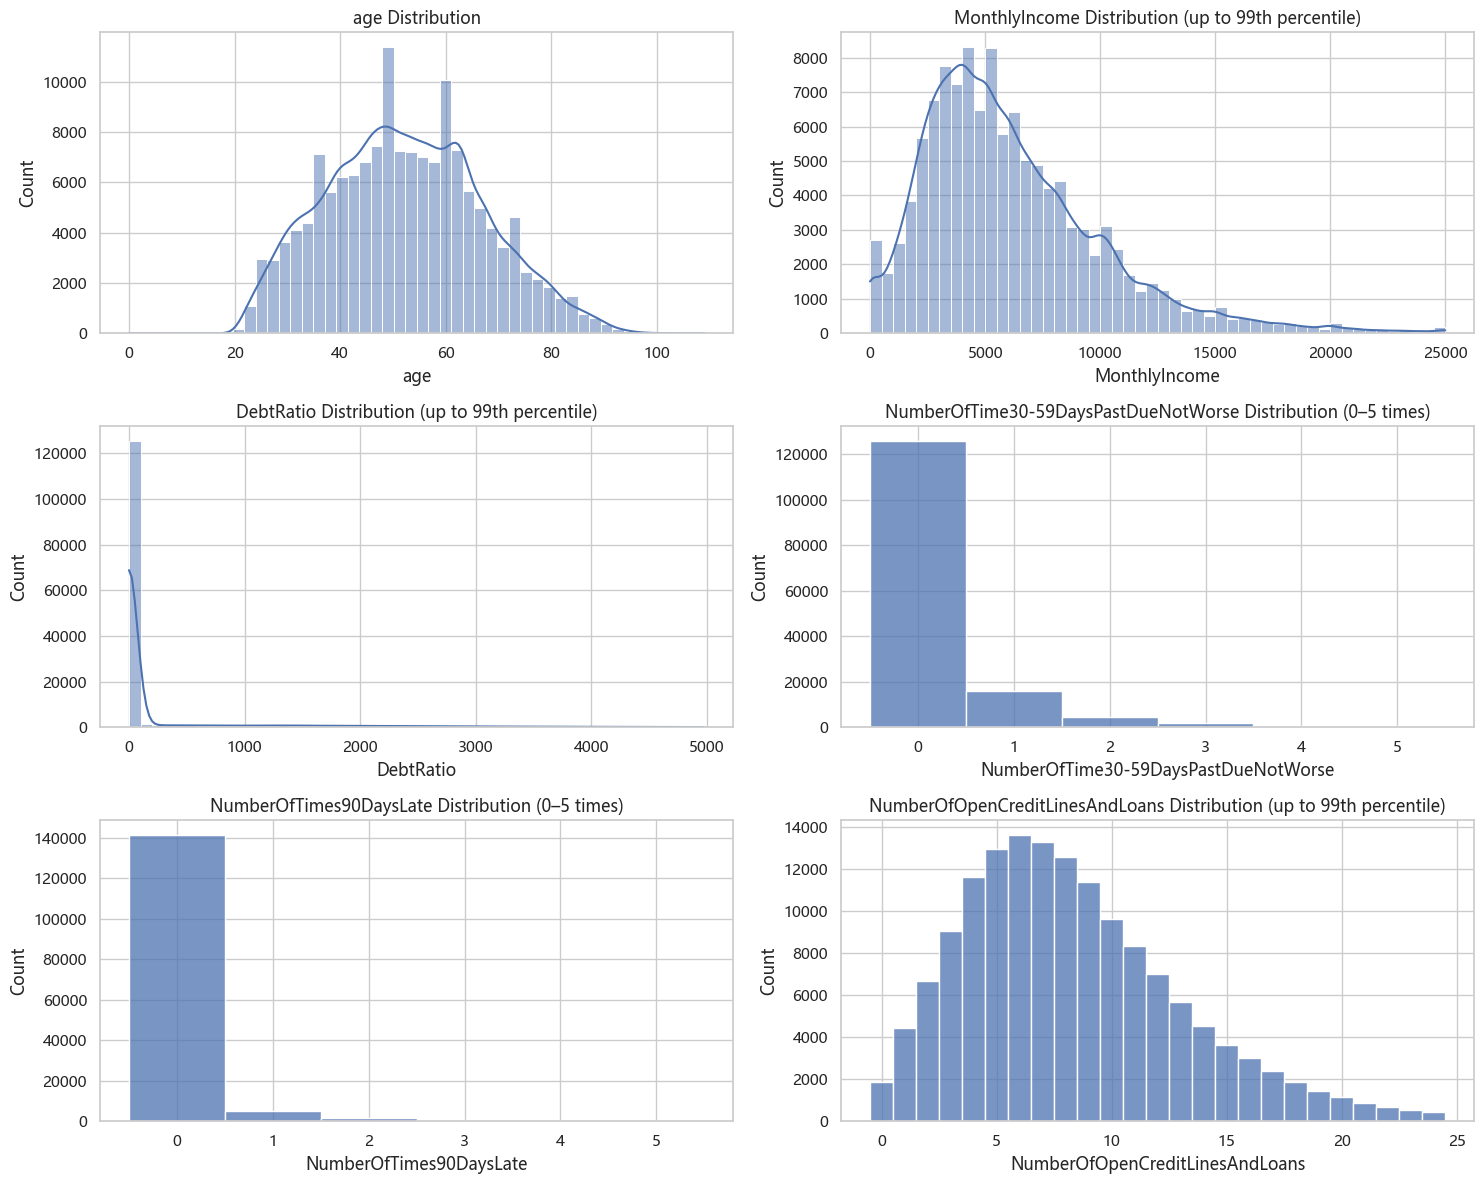

In [27]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

xdata = [
    'age',
    'MonthlyIncome',
    'DebtRatio',
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
    'NumberOfOpenCreditLinesAndLoans'
]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(xdata):
    values = df[col].dropna()
#处理有严重拖尾的连续变量，只画99%分位数以内的数据
    if col == 'MonthlyIncome':
        # 只展示月收入 99% 分位数以内的主体
        upper = values.quantile(0.99)
        sns.histplot(data=values[values <= upper], bins=50, kde=True, ax=axes[i])
        axes[i].set_title(f'{col} Distribution (up to 99th percentile)')

    elif col == 'DebtRatio':
        # 只展示债务比率 99% 分位数以内的主体
        upper = values.quantile(0.99)
        sns.histplot(data=values[values <= upper], bins=50, kde=True, ax=axes[i])
        axes[i].set_title(f'{col} Distribution (up to 99th percentile)')
#处理类别和离散次数的变量
    elif col in [
        'NumberOfTime30-59DaysPastDueNotWorse',
        'NumberOfTimes90DaysLate'
    ]:
        # 逾期次数是离散变量，整数次数分别成箱；这里只展示 0–5 次
        shown = values[values <= 5]
        sns.histplot(
            data=shown,
            bins=np.arange(-0.5, 6.5, 1),
            kde=False,
            ax=axes[i]
        )
        axes[i].set_xticks(range(6))
        axes[i].set_title(f'{col} Distribution (0–5 times)')

    elif col == 'NumberOfOpenCreditLinesAndLoans':
        # 笔数也是离散变量，按整数分别成箱
        upper = int(values.quantile(0.99))
        shown = values[values <= upper]
        sns.histplot(
            data=shown,
            bins=np.arange(-0.5, upper + 1.5, 1),
            kde=False,
            ax=axes[i]
        )
        axes[i].set_title(f'{col} Distribution (up to 99th percentile)')

    else:
        # 年龄：保留完整范围
        sns.histplot(data=values, bins=50, kde=True, ax=axes[i])
        axes[i].set_title(f'{col} Distribution')

    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()

1.年龄：整体分布呈现右偏，年龄偏低和偏高的人群占比较小，主要分布在30-70岁人群
2.月收入：严重右偏长尾分布，0附近存在尖峰，说明研究目标人群大多为中低收入，有个别极高收入拖长尾部，提示后续模型可以使用对数变换
3.债务比率:严重右偏长尾分布，0附近存在尖峰，说明研究目标人群大多债务比率较低